<a href="https://colab.research.google.com/github/MichalSlowakiewicz/Large-Scale-Machine-Learning/blob/master/LAB_5_mslowakiewicz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scaling Laws

During this laboratory we will explore scaling laws, an important part of understanding large models. We will try to replicate some of the results of Training Compute-Optimal Large Language Models (https://arxiv.org/abs/2203.15556). You may find the [slides from the last lecture](https://docs.google.com/presentation/d/1pAeSSmt6jaebXuSI7nJf3EKj2nzldTWlArFkNogtZLs/edit#slide=id.p) helpful.

As the authors of the original paper did not release details of all experiments used to produce the final fit, we will use the data extracted from the plots on this paper by the authors of Chinchilla Scaling: A Replication Attempt (https://arxiv.org/abs/2404.10102). They released their analysis under a github repository (https://github.com/epoch-research/analyzing-chinchilla).

Let's start by loading the data.

In [31]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim
from itertools import product
from tqdm.notebook import tqdm
import plotly.graph_objects as go

In [32]:
!git clone https://github.com/epoch-research/analyzing-chinchilla

fatal: destination path 'analyzing-chinchilla' already exists and is not an empty directory.


In [33]:
data = pd.read_csv('analyzing-chinchilla/data/svg_extracted_data.csv')

## Exercise 1: Understanding the problem

Take a look into the [Scaling Laws paper](https://arxiv.org/abs/2203.15556) by Hoffmann et al. Read the introduction. Find answers to the following questions/problems in the paper:
  

1.   What is the main research question authors are investigating?
2.   Briefly explain the method taken in Approach 1 (Sec. 3.1).
3.   Briefly explain the method taken in Approach 2 (Sec. 3.2).
4.   Briefly explain the method taken in Approach 3 (Sec. 3.3).

Can you identify any advantages or disadvantages of Approach 3 compared to the previous ones?

**Answers:**


1. The authors investigate how to optimally use a fixed compute budget (in FLOPs). They aim to answer how to balance model size and the number of tokens to achieve minimal training loss.
2. They train a fixed family of models (from 70M to 10B) for various token counts to obtain the minimal loss that can be achieved with a given budget.
3. Now, they fix a specific FLOPs budget and vary the model size for each budget. Then, they fit parabolas and directly obtain the optimal model size at the minimum of each curve.
4. In this approach, they fit a loss function (with parts responsible for both model size and token count) to the results obtained in the two previous approaches. Then, they obtain analytically the optimal model size-token count trade-off.

## Exercise 2: Understanding the data

In this exercise we will examine the data from experiments and make sure they are complete. You may find the function `num_to_readable` (from the cell below) helpful in printing the numbers in human readable format.

In [34]:
def num_to_readable(num):
    if 1e6 <= num < 1e9:
        return f"{num/1e6:.2f}M"
    elif 1e9 <= num < 1e12:
        return f"{num/1e9:.2f}B"
    elif 1e12 <= num < 1e15:
        return f"{num/1e12:.2f}T"
    elif num >= 1e15:
        return f"{num:.5e}"
    elif isinstance(num, float):
        return f"{num:.6}"
    else:
        return f"{num}"

1.   The downloaded data contain columns corresponding to training FLOPs $C$, and model size $N$. Please add a column with dataset size $D$ using a commonly used heuristic for calculating the training cost for Transformers:
$$C=6ND.$$


In [35]:
data["Tokens"] = data['Training FLOP'] / 6 / data['Model Size']

In [36]:
data

,x,y,color,Model Size,Training FLOP,hex_color,loss,Tokens
0,154.03592,140.63364,#faebdd,6.795600e+09,9.993853e+18,#faebdd,5.005582,2.451060e+08
1,151.60375,175.51709,#f8d1b8,2.979521e+09,9.227541e+18,#f8d1b8,4.665232,5.161647e+08
2,153.29233,180.65761,#f47a54,2.638631e+09,9.753047e+18,#f47a54,3.765563,6.160421e+08
3,152.88216,186.78615,#f47d57,2.282804e+09,9.622708e+18,#f47d57,3.793872,7.025502e+08
4,153.35068,192.24076,#ed503e,2.006673e+09,9.771731e+18,#ed503e,3.446995,8.116029e+08
...,...,...,...,...,...,...,...,...
240,302.37174,198.50406,#591e50,1.730547e+09,1.296639e+21,#591e50,2.286446,1.248775e+11
241,312.28760,186.78606,#531e4d,2.282809e+09,1.795036e+21,#531e4d,2.249076,1.310546e+11
242,319.95230,180.65752,#4e1d4b,2.638636e+09,2.308123e+21,#4e1d4b,2.222281,1.457902e+11
243,323.82795,175.51700,#4c1d4b,2.979528e+09,2.621011e+21,#4c1d4b,2.212313,1.466122e+11


2.   Examine the data: find the number of experiments, smallest and largest one (in terms of FLOPs), the range of model and dataset sizes.

In [37]:
print("Number of experiments:", len(data))

id_min = data["Training FLOP"].argmin()
id_max = data['Training FLOP'].argmax()

print("="*80)
print(f"Smallest experiment (FLOPs={(data['Training FLOP'].iloc[id_min])}):\n{data.iloc[id_min]}")
print("="*80)
print(f"Largest experiment (FLOPs={(data['Training FLOP'].iloc[id_max])}):\n{data.iloc[id_max]}")

min_model = data['Model Size'].min()
max_model = data['Model Size'].max()

print("="*80)
print(f"Model size range: {num_to_readable(min_model)} - {num_to_readable(max_model)}")

min_dataset = data['Tokens'].min()
max_dataset = data['Tokens'].max()

print("="*80)
print(f"Dataset range: {num_to_readable(min_dataset)} - {num_to_readable(max_dataset)}")

Number of experiments: 245
Smallest experiment (FLOPs=1.3972367362937152e+18):
x                             94.05376
y                             331.9645
color                          #ec4a3e
Model Size             73824671.648674
Training FLOP    1397236736293715200.0
hex_color                      #ec4a3e
loss                          3.405928
Tokens               3154403320.484937
Name: 47, dtype: object
Largest experiment (FLOPs=1.2956022673438285e+22):
x                                372.54603
y                                140.63355
color                              #34193d
Model Size               6795614805.310381
Training FLOP    12956022673438284972032.0
hex_color                          #34193d
loss                              2.077394
Tokens                 317754489343.968811
Name: 244, dtype: object
Model size range: 57.33M - 16.18B
Dataset range: 245.11M - 317.75B


3.   Let's try to get an idea of the scale of the experiments:

* Calculate the total amount of FLOPs (the sum) in all of them. Compare this value to the FLOPs used to train the main Chinchilla model (you can read the latter value from Figure 1 in the paper).
* According to the [data sheet](https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/a100/pdf/nvidia-a100-datasheet-us-nvidia-1758950-r4-web.pdf) of NVIDIA A100, it operates at 312 TFLOPs ($=312\cdot 10^{12}$) per second. Let's imagine we want to replicate the results of the paper by renting A100s in the cloud. Assuming MFU of 50% (that is, effectively our code runs on the GPU at 156 TFLOPs/s), estimate the number of GPU-hours that would be needed to run all of the experiments in our table and their cost (A100 in the preemptible mode costs around $2/hour).

In [38]:
total_flops = data['Training FLOP'].sum()
print("Total amount of FLOPs:", total_flops, "FLOPS")
print("FLOPs used to train Chinchilla:", 5.76e23)
print("Total hours needed:", total_flops / (156 * 1e12) / 3600, "hours")
print("Total cost:", total_flops / (156 * 1e12) / 3600 * 2, "dollars")

Total amount of FLOPs: 1.051809089538968e+23 FLOPS
FLOPs used to train Chinchilla: 5.76e+23
Total hours needed: 187287.94329397578 hours
Total cost: 374575.88658795157 dollars


## Exercise 3: Replicating Approach 2

In this exercise, we will replicate Approach 2: IsoFLOP profiles from the paper.

1. For each budget from the list in the cell below, find the experiments, where
$$|\log(\text{experiment_budget})-\log(\text{closest_budget_from_list})| < 0.2.$$
We will use only these experiments in the analysis in this exercise.

In [39]:
flop_budgets = [6e18, 1e19, 3e19, 6e19, 1e20, 3e20, 6e20, 1e21, 3e21]

In [40]:
def calculate_closest_budget(budget):
    closest_budget = min(flop_budgets, key=lambda x: abs(x - budget))
    return closest_budget

In [41]:
def calculate_closest_budget_and_distance(flops_list):
    dist_log = [abs(np.log(flops_list) - np.log(b)) for b in flop_budgets]
    id_min = np.argmin(dist_log)
    return flop_budgets[id_min], dist_log[id_min]

data_2 = data['Training FLOP'].apply(calculate_closest_budget_and_distance)

# dividing our data into two vectors - closest budgets and their log distances
closest_budgets = data_2.apply(lambda x: x[0])
dist_log = data_2.apply(lambda x: x[1])

# applying restriction
mask = dist_log < 0.2

data_filtered = data[mask].copy()
data_filtered["budget_group"] = closest_budgets[mask]

In [42]:
data_filtered

,x,y,color,Model Size,Training FLOP,hex_color,loss,Tokens,budget_group
0,154.03592,140.63364,#faebdd,6.795600e+09,9.993853e+18,#faebdd,5.005582,2.451060e+08,1.000000e+19
1,151.60375,175.51709,#f8d1b8,2.979521e+09,9.227541e+18,#f8d1b8,4.665232,5.161647e+08,1.000000e+19
2,153.29233,180.65761,#f47a54,2.638631e+09,9.753047e+18,#f47a54,3.765563,6.160421e+08,1.000000e+19
3,152.88216,186.78615,#f47d57,2.282804e+09,9.622708e+18,#f47d57,3.793872,7.025502e+08,1.000000e+19
4,153.35068,192.24076,#ed503e,2.006673e+09,9.771731e+18,#ed503e,3.446995,8.116029e+08,1.000000e+19
...,...,...,...,...,...,...,...,...,...
231,293.75688,201.58295,#5e1f52,1.609083e+09,9.774574e+20,#5e1f52,2.314015,1.012437e+11,1.000000e+21
232,293.32536,206.59748,#611f53,1.429236e+09,9.637196e+20,#611f53,2.331417,1.123817e+11,1.000000e+21
233,293.64765,211.74199,#611f53,1.265596e+09,9.739615e+20,#611f53,2.331417,1.282613e+11,1.000000e+21
238,257.26564,230.29248,#751f58,8.163432e+08,2.953043e+20,#751f58,2.445913,6.029005e+10,3.000000e+20


2. For each budget group, fit a parabola in the log-log scale between number of parameters and loss (i.e. x scale is $\log(\text{params})$ and y scale is $\log(\text{loss})$, as in the image from the paper below). Find the minimum of each parabola - this is our estimated optimal model size for each budget group. Plot the points together with the fitted parabolas to create a plot similar to the one from the publication. Finally, list the estimated optimal number of parameters, training tokens, and corresponding token to parameter ratio for each budget group.

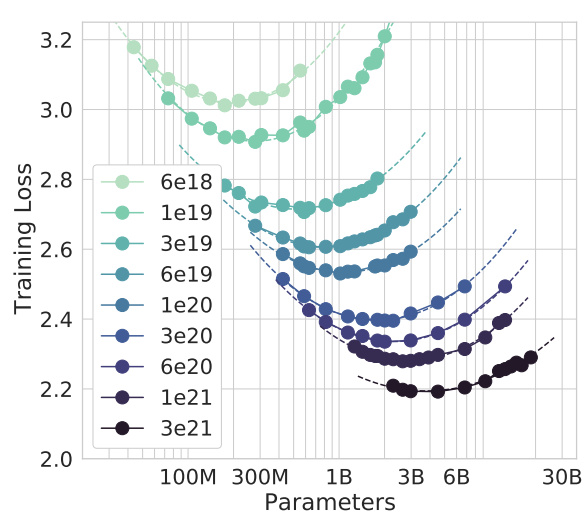

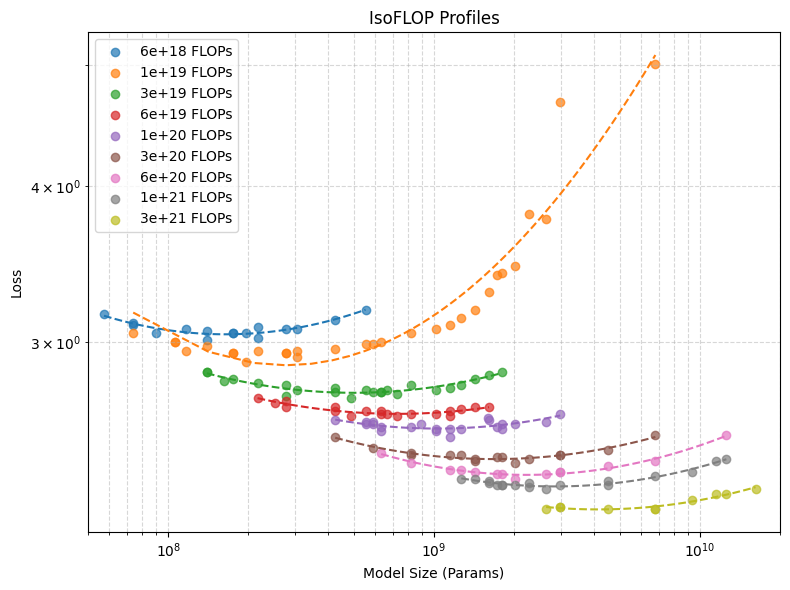

In [43]:
plt.figure(figsize=(8, 6))
parabolas = {}

# loop for fitting parabolas
for budget, group in data_filtered.groupby('budget_group'):
    x = np.log10(group['Model Size'].values)
    y = np.log10(group['loss'].values)

    # fitting parabolas to the data
    coeffs = np.polyfit(x, y, 2)
    parabolas[budget] = coeffs

    # data points
    plt.scatter(group['Model Size'], group['loss'], alpha=0.7, label=f"{budget:.0e} FLOPs")

    # points for plotting parabola
    x_range = np.linspace(group['Model Size'].min(), group['Model Size'].max(), 100)
    x_log = np.log10(x_range)
    y_log_pred = coeffs[0] * (x_log ** 2) + coeffs[1] * x_log + coeffs[2]
    y_pred = 10 ** y_log_pred

    plt.plot(x_range, y_pred,  linestyle='--')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Model Size (Params)')
plt.ylabel('Loss')
plt.title('IsoFLOP Profiles')
plt.legend(loc='upper left')
plt.xlim(5.0e+7, 2.0e+10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [44]:
# TODO: plot
# (the figure below is the expected result - running this cell clears it)

In [54]:
def fit_parabola_and_find_min(group):
    x, y = np.log10(group['Model Size'].values), np.log10(group['loss'].values)

    # fitting parabola
    coeffs = np.polyfit(x, y, 2)

    # getting optimal sizes
    optimal_log_size = - coeffs[1] / (2 * coeffs[0])
    optimal_model_size = 10 ** optimal_log_size

    predicted_min_log_loss = coeffs[0] * (optimal_log_size ** 2) + coeffs[1] * optimal_log_size + coeffs[2]
    predicted_min_loss = 10 ** predicted_min_log_loss

    # Return the results
    return pd.DataFrame({
        'budget_group': [group.name],
        'optimal_model_size': [optimal_model_size],
        'predicted_min_loss': [predicted_min_loss]
    })


In [46]:
# Apply the function to each budget_group
results = data_filtered.groupby('budget_group').apply(fit_parabola_and_find_min)

# Reset index to flatten the DataFrame
results = results.reset_index(drop=True)

/tmp/ipykernel_2203/1277298891.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = data_filtered.groupby('budget_group').apply(fit_parabola_and_find_min)


In [55]:
results["optimal_tokens"] = results['budget_group'] / 6 / results['optimal_model_size'] # using formula C = 6ND
results["token_param_ratio"] = results['optimal_tokens'] / results['optimal_model_size']
results

,budget_group,optimal_model_size,predicted_min_loss,optimal_tokens,token_param_ratio
0,6.000000e+18,1.643204e+08,1.894871e-05,6.085671e+09,37.035395
1,1.000000e+19,2.763381e+08,9.484952e-10,6.031258e+09,21.825646
2,3.000000e+19,4.992376e+08,1.541440e-04,1.001527e+10,20.061133
3,6.000000e+19,7.300898e+08,3.155122e-04,1.369695e+10,18.760633
4,1.000000e+20,1.026432e+09,1.240052e-04,1.623748e+10,15.819350
5,3.000000e+20,1.677062e+09,9.240686e-05,2.981404e+10,17.777545
6,6.000000e+20,2.229523e+09,1.596870e-05,4.485264e+10,20.117591
7,1.000000e+21,2.845610e+09,2.401846e-05,5.856974e+10,20.582487
8,3.000000e+21,4.131841e+09,2.347455e-05,1.210114e+11,29.287532


## Exercise 4: Replicating Approach 3

In this exercise we will replicate Approach 3 from the paper: Fitting the Parametric Loss Function. Implement the fitting and fit the final formula. You can find the description of the process in Section 3.3 and D.2 of the paper. Make sure to use a grid of initializations and simply choose the initialization of parameters that allows to minimize RMSE on the data.

NOTE: L-BFGS minimizes the Huber loss in log space, not the RMSE, so the initialization with the smallest RMSE is not necessarily the one that fits best by the criterion that was actually optimized. Record both numbers for every initialization and check whether they pick the same winner.

In [48]:
N = torch.Tensor(data["Model Size"]).requires_grad_(False)
D = torch.Tensor(data["Tokens"]).requires_grad_(False)
L = torch.Tensor(data["loss"]).requires_grad_(False)

In [49]:
def predict_loss(N, a, alpha, D, b, beta, e):
    return a / N**alpha + b / D**beta + e

In [50]:
def rmse(L, L_pred):
    return torch.sqrt(torch.mean((L - L_pred) ** 2))

In [60]:
def compute_scaling_law(N, a, alpha, D, b, beta, e, L, huber_delta):
    """
    params:
    N, a, alpha, D, b, beta, e: initial values for the parameters of the scaling law
    huber_delta: delta parameter for the Huber loss
    """
    alpha = torch.Tensor([alpha]).requires_grad_(True)
    a = torch.Tensor([a]).requires_grad_(True)
    beta = torch.Tensor([beta]).requires_grad_(True)
    b = torch.Tensor([b]).requires_grad_(True)
    e = torch.Tensor([e]).requires_grad_(True)

    def objective(N, a, alpha, D, b, beta, e, L, delta):

        # calculating Huber loss
        L_pred = predict_loss(N, a, alpha, D, b, beta, e)
        L_pred = torch.clamp(L_pred, min=1e-5) # added to prevent numerical overflow

        logL_pred = torch.log(L_pred)
        logL = torch.log(L)

        loss = F.huber_loss(logL_pred, logL, delta=delta)

        return loss

    def closure():
        lbfgs.zero_grad()
        loss = objective(N, a, alpha, D, b, beta, e, L, huber_delta)
        loss.backward()
        return loss

    lbfgs = optim.LBFGS([a, alpha, b, beta, e],
                        history_size=10000,
                        lr=0.1,
                        max_iter=100000,
                        line_search_fn="strong_wolfe")

    lbfgs.step(closure)

    # obtaining the values
    A = a.item()
    alpha = alpha.item()
    B = b.item()
    beta = beta.item()
    E = e.item()

    return A, alpha, B, beta, E

In [64]:
huber_deltas = [0.001]
alpha_inits = [0.5, 1.0, 1.5]
beta_inits = [0.5, 1.0, 1.5]
a_inits = [5., 10., 15.]
b_inits = [5., 10., 15.]
e_inits = [-0.5, 0., 0.5]

# fit the scaling law for all combinations of the initializations above and
# collect the results in a DataFrame called df; the cell below sorts it, so it
# needs at least the columns "train_score", "A", "alpha", "B", "beta", "E"

results = []

# looping through all possible deltas, alphas, betas, a, b, e
for huber_delta, alpha, beta, a, b, e in product(huber_deltas, alpha_inits, beta_inits, a_inits, b_inits, e_inits):

  # using above function
  A, alpha, B, beta, E = compute_scaling_law(N, a, alpha, D, b, beta, e, L, huber_delta)

  # caclulating Huber and RMSE losses
  L_pred = predict_loss(N, A, alpha, D, B, beta, E)

  logL_pred = torch.log(L_pred)
  logL = torch.log(L)

  loss = F.huber_loss(logL_pred, logL, delta=huber_delta)
  loss = loss.item()

  loss_rmse = rmse(L, L_pred)
  loss_rmse = loss_rmse.item()


  results.append({"train_score": loss, "rmse": loss_rmse, "A": A, "alpha": alpha, "B": B, "beta": beta, "E": E})

df = pd.DataFrame(results)

In [65]:
df.sort_values("train_score")

,train_score,rmse,A,alpha,B,beta,E
25,0.000019,0.186514,15.084850,0.128970,15.001757,0.101102,0.158094
26,0.000019,0.187217,15.072194,0.128406,15.004912,0.101508,0.158849
17,0.000019,0.185216,10.042739,0.094843,15.003680,0.099585,-0.253203
14,0.000020,0.194954,10.086451,0.093143,10.006383,0.067449,-0.916978
13,0.000020,0.193949,10.091301,0.094381,10.004264,0.066614,-0.919298
...,...,...,...,...,...,...,...
228,NaN,3.194366,10.000000,1.500000,10.000000,1.500000,-0.500000
231,NaN,3.194366,10.000000,1.500000,15.000000,1.500000,-0.500000
234,NaN,3.194366,15.000000,1.500000,5.000000,1.500000,-0.500000
237,NaN,3.194366,15.000000,1.500000,10.000000,1.500000,-0.500000
